In [2]:
import pandas as pd

In [3]:

df = pd.read_excel("Bank Customer Churn Prediction.csv.xlsx")



In [4]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Shape: (10000, 12)

Columns:
['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']

Data types:
customer_id           int64
credit_score          int64
country              object
gender               object
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate customer IDs:", df["customer_id"].duplicated().sum())

Missing values:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Duplicate rows: 0

Duplicate customer IDs: 0


In [7]:
print("Unique values in binary columns:")

for col in ["credit_card", "active_member", "churn"]:
    print(col, sorted(df[col].unique()))

print("\nNumeric summary:")
print(df.describe())

print("\nCategorical values:")
print("Country:", df["country"].unique())
print("Gender:", df["gender"].unique())

Unique values in binary columns:
credit_card [np.int64(0), np.int64(1)]
active_member [np.int64(0), np.int64(1)]
churn [np.int64(0), np.int64(1)]

Numeric summary:
        customer_id  credit_score           age        tenure        balance  \
count  1.000000e+04  10000.000000  10000.000000  10000.000000   10000.000000   
mean   1.569094e+07    650.528800     38.921800      5.012800   76485.889288   
std    7.193619e+04     96.653299     10.487806      2.892174   62397.405202   
min    1.556570e+07    350.000000     18.000000      0.000000       0.000000   
25%    1.562853e+07    584.000000     32.000000      3.000000       0.000000   
50%    1.569074e+07    652.000000     37.000000      5.000000   97198.540000   
75%    1.575323e+07    718.000000     44.000000      7.000000  127644.240000   
max    1.581569e+07    850.000000     92.000000     10.000000  250898.090000   

       products_number  credit_card  active_member  estimated_salary  \
count     10000.000000  10000.00000   10000

In [8]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

under_18 = df[df["age"] < 18]

print("\nRows with age < 18:", len(under_18))
display(under_18)


Minimum age: 18
Maximum age: 92

Rows with age < 18: 0


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn


In [9]:

print("Number of duplicate customer IDs:", df["customer_id"].duplicated().sum())


Number of duplicate customer IDs: 0


In [10]:

print(df[["credit_score", "tenure", "products_number"]].describe())


       credit_score        tenure  products_number
count  10000.000000  10000.000000     10000.000000
mean     650.528800      5.012800         1.530200
std       96.653299      2.892174         0.581654
min      350.000000      0.000000         1.000000
25%      584.000000      3.000000         1.000000
50%      652.000000      5.000000         1.000000
75%      718.000000      7.000000         2.000000
max      850.000000     10.000000         4.000000


In [11]:

print(df[["balance", "estimated_salary"]].min())
print(df[["balance", "estimated_salary"]].max())



balance              0.00
estimated_salary    11.58
dtype: float64
balance             250898.09
estimated_salary    199992.48
dtype: float64


## EDA

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [13]:
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (10000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [14]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicated Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Distribution:")
print(df["churn"].value_counts())

Missing Values:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Duplicated Rows: 0

Data Types:
customer_id           int64
credit_score          int64
country              object
gender               object
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

Target Distribution:
churn
0    7963
1    2037
Name: count, dtype: int64


In [16]:
#Calculate Overall Churn Rate
total_customers = len(df)

churned_customers = df["churn"].sum()

retained_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Total Customers: 10,000
Churned Customers: 2,037
Retained Customers: 7,963
Overall Churn Rate: 20.37%


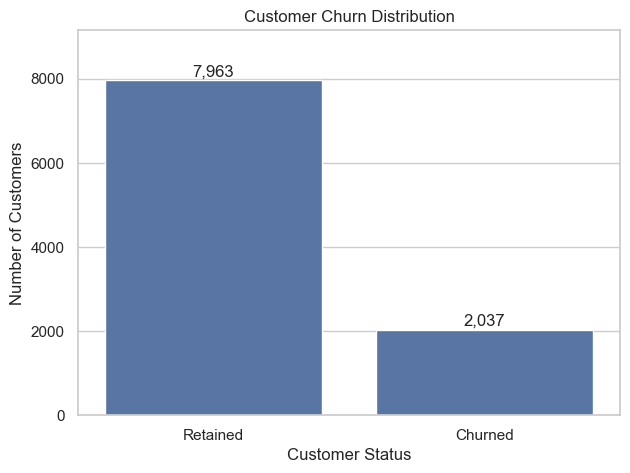

In [17]:
churn_counts = df["churn"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=["Retained", "Churned"],
    y=[churn_counts[0], churn_counts[1]]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for i, value in enumerate([churn_counts[0], churn_counts[1]]):
    ax.text(i, value + 100, f"{value:,}", ha="center")

plt.ylim(0, max(churn_counts) * 1.15)
plt.show()

### Finding 1: Overall Customer Churn

**Finding:** The overall customer churn rate is 20.37%.

**Evidence:** Out of 10,000 customers, 2,037 churned and
7,963 were retained.

**So What:**

## Churn Analysis by Country

In [18]:
df["country"].value_counts()

country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [20]:
#Calculate el Churn Rate le kol Country
country_churn = df.groupby("country")["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

country_churn["churn_rate"] *= 100

country_churn = country_churn.sort_values(
    by="churn_rate",
    ascending=False
)

country_churn

,country,total_customers,churned_customers,churn_rate
1,Germany,2509,814,32.443204
2,Spain,2477,413,16.673395
0,France,5014,810,16.154767


## Visualize Churn Rate by Country

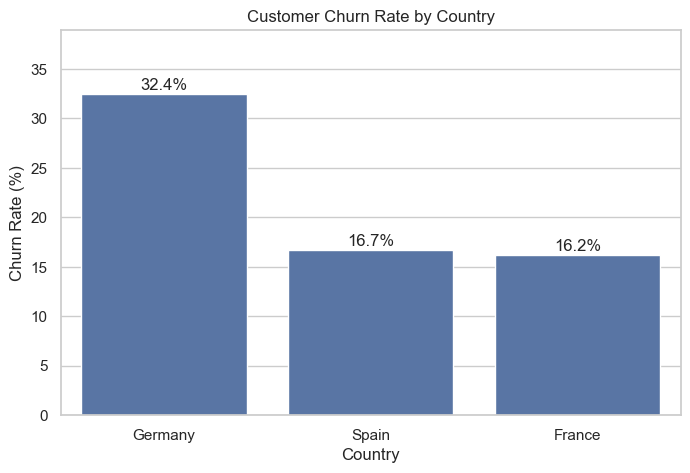

In [21]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=country_churn,
    x="country",
    y="churn_rate"
)

plt.title("Customer Churn Rate by Country")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(country_churn["churn_rate"]):
    ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.ylim(0, country_churn["churn_rate"].max() * 1.2)
plt.show()

### Finding 2: Customer Churn by Country

**Finding:** To be determined from the analysis.

**Evidence:** Compare the churn rate and total number of
customers for each country.

**So What:** Identify which geographical customer groups
may require further investigation.

## Churn Analysis by Gender

## Business Question: Does customer churn differ between male and female customers?!!

In [25]:
df["gender"].value_counts()

gender
Male      5457
Female    4543
Name: count, dtype: int64

In [26]:
# calculate el churn beta3 el male we el female
gender_churn = df.groupby("gender")["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

gender_churn["churn_rate"] *= 100

gender_churn = gender_churn.sort_values(
    by="churn_rate",
    ascending=False
)

gender_churn


,gender,total_customers,churned_customers,churn_rate
0,Female,4543,1139,25.071539
1,Male,5457,898,16.455928


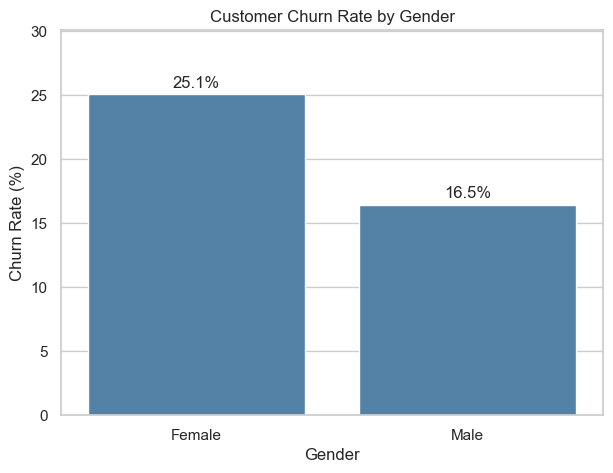

In [28]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_churn,
    x="gender",
    y="churn_rate",
    color="steelblue"
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(gender_churn["churn_rate"]):
    ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.ylim(0, gender_churn["churn_rate"].max() * 1.2)

plt.show()

### Finding 3: Customer Churn by Gender

**Finding:** [Which group has the higher churn rate?]

**Evidence:** [Churn rate, churned customers,
and total customers for both groups.]

**So What:** The observed difference can help identify
customer segments for further investigation.

## Churn Analysis by Active Membership

In [29]:
active_churn = df.groupby("active_member")["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

active_churn["churn_rate"] *= 100

active_churn["membership_status"] = active_churn["active_member"].map({
    0: "Inactive",
    1: "Active"
})

active_churn = active_churn.sort_values(
    by="churn_rate",
    ascending=False
)

active_churn

,active_member,total_customers,churned_customers,churn_rate,membership_status
0,0,4849,1302,26.850897,Inactive
1,1,5151,735,14.269074,Active


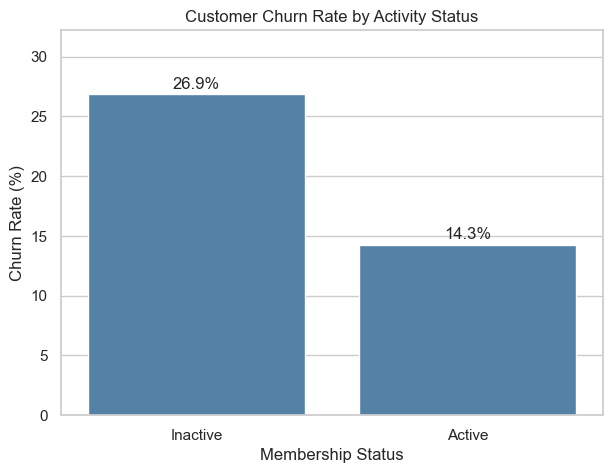

In [30]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=active_churn,
    x="membership_status",
    y="churn_rate",
    color="steelblue"
)

plt.title("Customer Churn Rate by Activity Status")
plt.xlabel("Membership Status")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(active_churn["churn_rate"]):
    ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.ylim(0, active_churn["churn_rate"].max() * 1.2)

plt.show()

### Finding 4: Customer Churn by Active Membership

**Finding:** [Identify whether active or inactive customers
have a higher churn rate.]

**Evidence:** [Include the churn rate, number of churned
customers, and total customers for both groups.]

**So What:** Understanding the relationship between
customer activity and churn may help the bank identify
segments that need additional retention attention.

## Churn Analysis by Credit Card Ownership

In [31]:
credit_churn = df.groupby("credit_card")["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

credit_churn["churn_rate"] *= 100

credit_churn["credit_card_status"] = credit_churn["credit_card"].map({
    0: "No Credit Card",
    1: "Has Credit Card"
})

credit_churn = credit_churn.sort_values(
    by="churn_rate",
    ascending=False
)

credit_churn

,credit_card,total_customers,churned_customers,churn_rate,credit_card_status
0,0,2945,613,20.814941,No Credit Card
1,1,7055,1424,20.184266,Has Credit Card


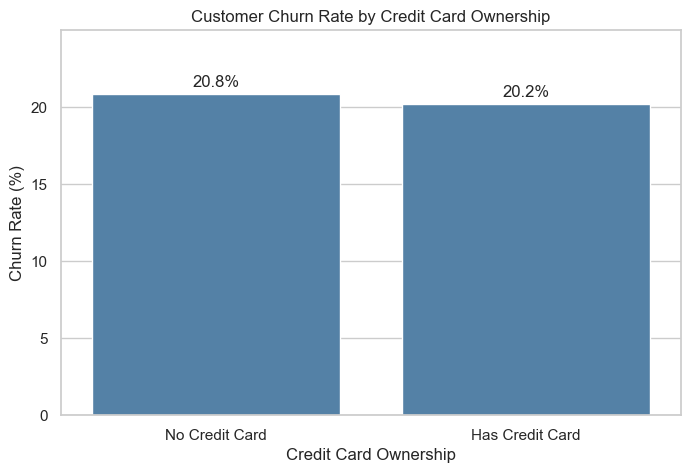

In [32]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=credit_churn,
    x="credit_card_status",
    y="churn_rate",
    color="steelblue"
)

plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Credit Card Ownership")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(credit_churn["churn_rate"]):
    ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.ylim(0, credit_churn["churn_rate"].max() * 1.2)

plt.show()

### Finding 5: Customer Churn by Credit Card Ownership

**Finding:** [Identify which customer group has the higher churn rate.]

**Evidence:** [Include the churn rate, number of churned customers, and total customers in each group.]

**So What:** Comparing churn rates across credit card ownership groups can help determine whether this characteristic deserves further investigation as a potential churn indicator.

## Churn Analysis by Number of Products

In [33]:
df["products_number"].value_counts().sort_index()

products_number
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [34]:
products_churn = df.groupby("products_number")["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

products_churn["churn_rate"] *= 100

products_churn = products_churn.sort_values(
    by="products_number"
)

products_churn

,products_number,total_customers,churned_customers,churn_rate
0,1,5084,1409,27.714398
1,2,4590,348,7.581699
2,3,266,220,82.706767
3,4,60,60,100.000000


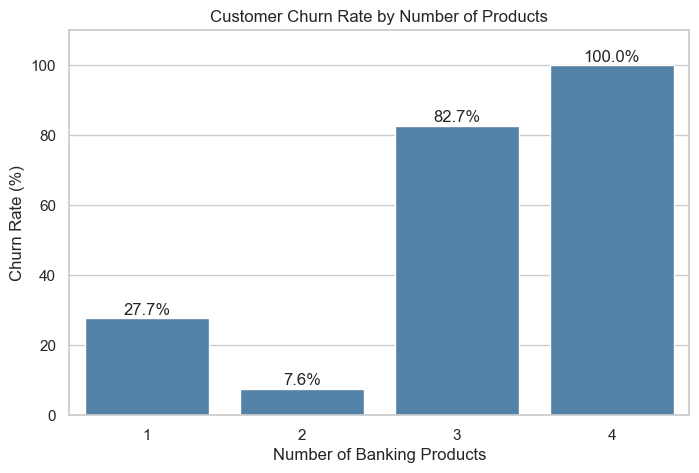

In [35]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=products_churn,
    x="products_number",
    y="churn_rate",
    color="steelblue"
)

plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Banking Products")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(products_churn["churn_rate"]):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 110)
plt.show()

### Finding 6: Customer Churn by Number of Products

**Finding:** [Identify which product groups have the
highest and lowest churn rates.]

**Evidence:** [Include churn rates, churned customers,
and total customers for each group.]

**So What:** Differences in churn rates across product
groups may help the bank identify customers who need
additional retention attention.

## Churn Analysis by Age Groups

In [36]:
#Create Age Groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 30, 40, 50, 60, float("inf")],
    labels=["Under 30", "30-39", "40-49", "50-59", "60+"],
    right=False
)

df["age_group"].value_counts().sort_index()

age_group
Under 30    1641
30-39       4346
40-49       2618
50-59        869
60+          526
Name: count, dtype: int64

In [37]:
#calc
age_churn = df.groupby(
    "age_group",
    observed=True
)["churn"].agg(
    total_customers="count",
    churned_customers="sum",
    churn_rate="mean"
).reset_index()

age_churn["churn_rate"] *= 100

age_churn

,age_group,total_customers,churned_customers,churn_rate
0,Under 30,1641,124,7.556368
1,30-39,4346,473,10.883571
2,40-49,2618,806,30.786860
3,50-59,869,487,56.041427
4,60+,526,147,27.946768


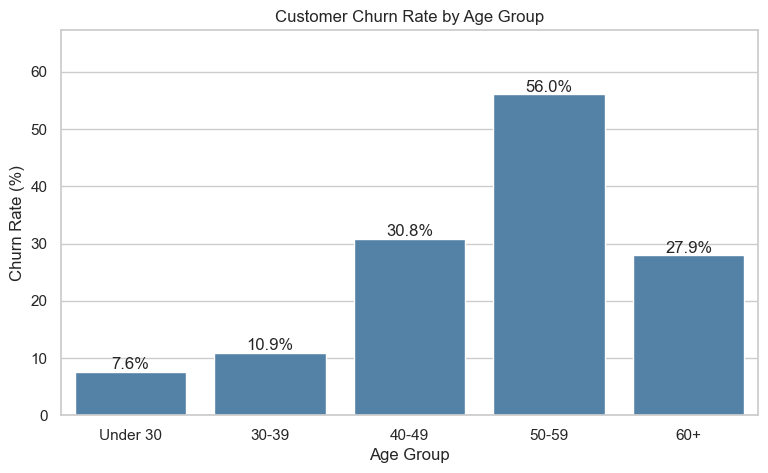

In [38]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_churn,
    x="age_group",
    y="churn_rate",
    color="steelblue"
)

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(age_churn["churn_rate"]):
    ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.ylim(0, age_churn["churn_rate"].max() * 1.2)

plt.show()

### Finding 7: Customer Churn by Age Group

**Finding:** [Identify the age group with the highest churn rate.]

**Evidence:** [Compare churn rates, churned customers, and total customers across all age groups.]

**So What:** Understanding which age groups have higher churn rates can help the bank investigate potential retention challenges among different customer segments.

## Numerical Features Analysis

In [39]:
numerical_cols = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "estimated_salary"
]

numeric_summary = df.groupby("churn")[numerical_cols].agg(
    ["mean", "median"]
)

numeric_summary

credit_score               age           tenure              balance  \
              mean median       mean median      mean median          mean   
churn                                                                        
0       651.853196  653.0  37.408389   36.0  5.033279    5.0  72745.296779   
1       645.351497  646.0  44.837997   45.0  4.932744    5.0  91108.539337   

                 estimated_salary             
          median             mean     median  
churn                                         
0       92072.68     99738.391772   99645.04  
1      109349.29    101465.677531  102460.84

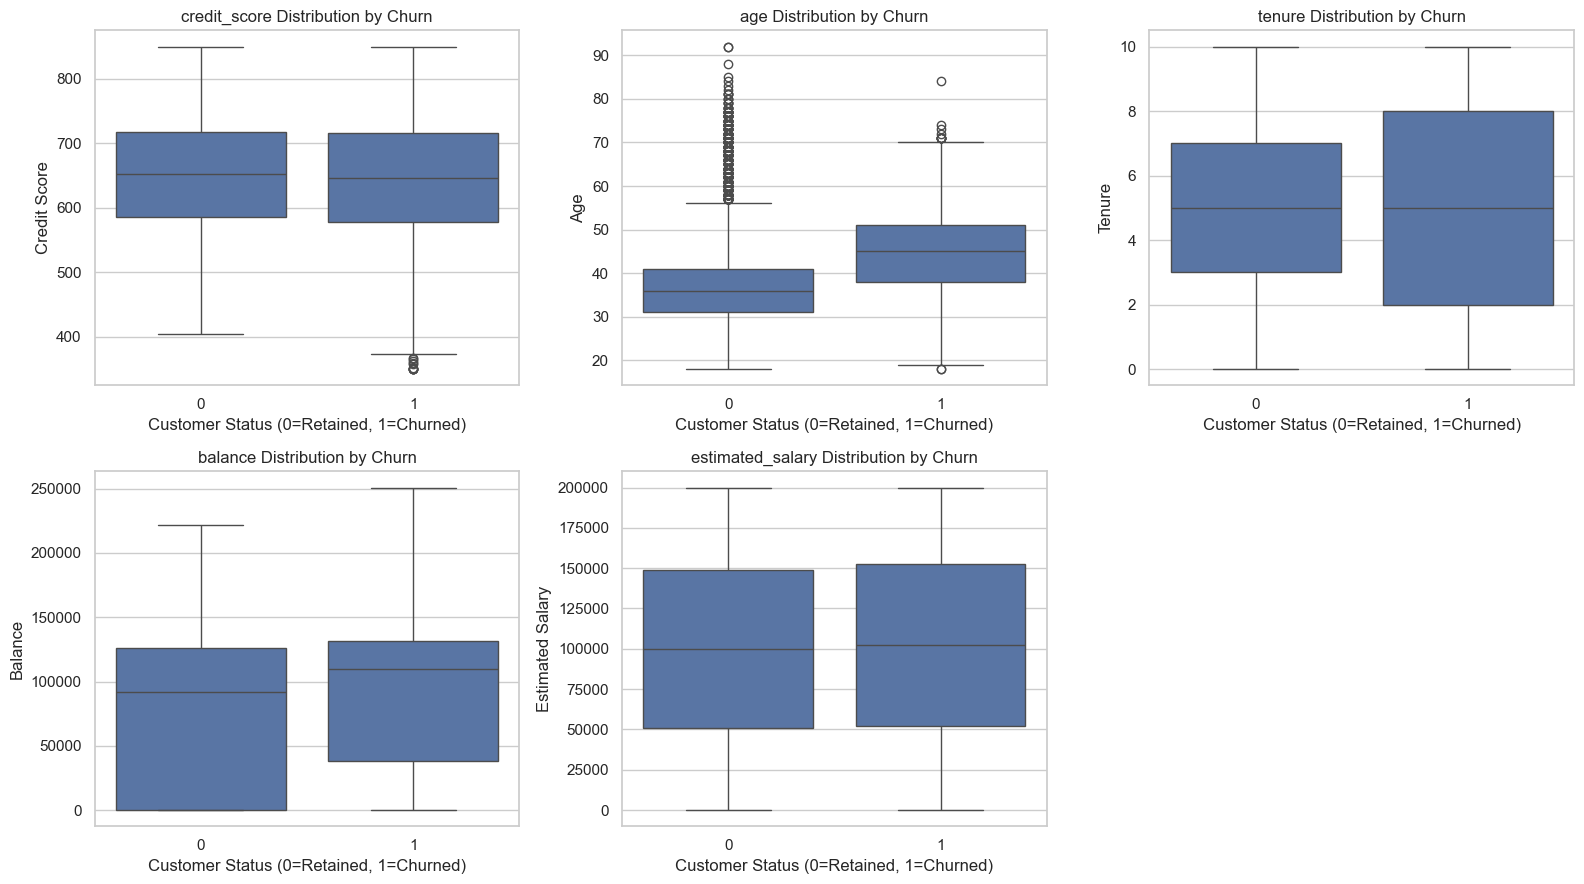

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, numerical_cols):

    sns.boxplot(
        data=df,
        x="churn",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} Distribution by Churn")
    ax.set_xlabel("Customer Status (0=Retained, 1=Churned)")
    ax.set_ylabel(col.replace("_", " ").title())

for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Finding 8: Numerical Characteristics of Churned Customers

**Finding:** [Identify the clearest numerical difference
between churned and retained customers.]

**Evidence:** [Compare the mean and median values
for both groups and mention their sample sizes.]

**So What:** Understanding these differences can help
identify customer characteristics associated with
higher churn risk.

## Correlation

In [42]:
# correlation matrix
corr_cols = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "products_number",
    "credit_card",
    "active_member",
    "estimated_salary",
    "churn"
]

corr_matrix = df[corr_cols].corr()

corr_matrix

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
credit_score,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094
age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323
tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001
balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533
products_number,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820
credit_card,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138
active_member,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128
estimated_salary,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097
churn,-0.027094,0.285323,-0.014001,0.118533,-0.047820,-0.007138,-0.156128,0.012097,1.000000


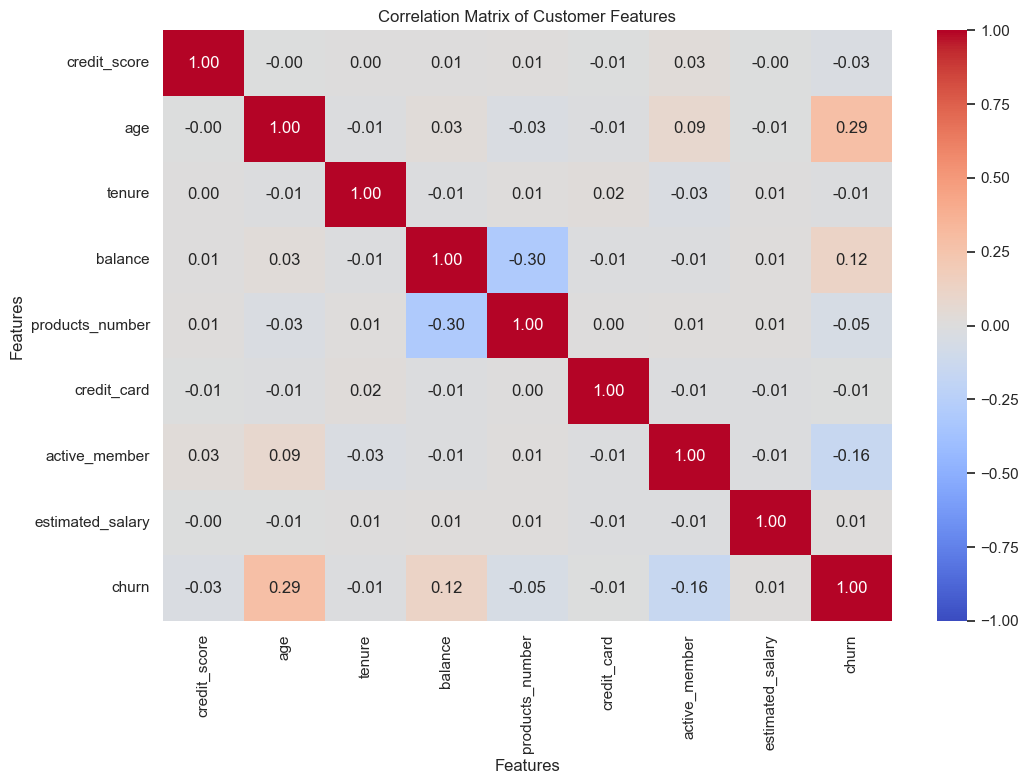

In [43]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Customer Features")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [44]:
churn_correlation = corr_matrix["churn"].drop("churn")

churn_correlation = churn_correlation.reindex(
    churn_correlation.abs().sort_values(ascending=False).index
)

churn_correlation

age                 0.285323
active_member      -0.156128
balance             0.118533
products_number    -0.047820
credit_score       -0.027094
tenure             -0.014001
estimated_salary    0.012097
credit_card        -0.007138
Name: churn, dtype: float64

### Correlation Analysis

**Finding:** [Identify the numerical features with the
strongest positive and negative correlations with churn.]

**Evidence:** [Report the actual correlation coefficients
from the correlation matrix.]

**So What:** The results help identify features that may
be useful for further churn investigation.

**Important:** Correlation does not imply causation.
These results describe statistical associations rather
than proving why customers leave the bank.

## Statistical Test 1 Chi-Square Test

In [45]:
from scipy.stats import chi2_contingency

country_table = pd.crosstab(
    df["country"],
    df["churn"]
)

country_table

churn,0,1
country,,
France,4204,810
Germany,1695,814
Spain,2064,413


In [47]:
#Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    country_table
)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of Freedom: {dof}")

print("\nMinimum Expected Frequency:", expected.min())

Chi-Square Statistic: 301.2553
P-value: 3.83032e-66
Degrees of Freedom: 2

Minimum Expected Frequency: 504.5649


In [48]:
#Interpret the Result
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is a statistically significant association "
          "between country and customer churn.")
else:
    print("Fail to reject H0")
    print("There is insufficient evidence of an association "
          "between country and customer churn.")

Reject H0
There is a statistically significant association between country and customer churn.


### Statistical Test 1: Chi-Square Test

**Objective:** To investigate whether country and customer churn are statistically associated.

**Test Used:** Chi-Square Test of Independence.

**Null Hypothesis (H0):** Country and churn are independent.

**Alternative Hypothesis (H1):** Country and churn are associated.

**Significance Level:** 0.05

**Results:**
- Chi-Square Statistic: [Insert result]
- P-value: [Insert result]
- Degrees of Freedom: [Insert result]

**Interpretation:** [Explain whether H0 was rejected and what this means for customer churn.]

**Business Implication:** The result helps assess whether differences in customer churn across countries warrant further investigation.

## Mann-Whitney U Test
me4 3aref da eh (chat gpt)

In [49]:
retained_age = df[df["churn"] == 0]["age"]

churned_age = df[df["churn"] == 1]["age"]

In [ ]:
# check el group size

print("Retained Customers:", len(retained_age))
print("Churned Customers:", len(churned_age))

print("Retained Median Age:", retained_age.median())
print("Churned Median Age:", churned_age.median())

Retained Customers: 7963
Churned Customers: 2037
Retained Median Age: 36.0
Churned Median Age: 45.0


### Statistical Test 2: Mann-Whitney U Test

**Business Question:**
Is there a statistically significant difference in age
distributions between churned and retained customers?

**H0 (Null Hypothesis):**
The age distributions of churned and retained customers
are the same.

**H1 (Alternative Hypothesis):**
The age distributions are different.

**Significance Level:** 0.05

## Run Mann-Whitney U Test

In [51]:
from scipy.stats import mannwhitneyu

u_stat, p_value_age = mannwhitneyu(
    retained_age,
    churned_age,
    alternative="two-sided"
)

print(f"U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value_age:.6g}")

U Statistic: 4345981.50
P-value: 3.2104e-230


In [52]:
alpha = 0.05

if p_value_age < alpha:
    print("Reject H0")
    print("There is a statistically significant difference "
          "in age distributions between the two groups.")
else:
    print("Fail to reject H0")
    print("There is insufficient statistical evidence "
          "of a difference in age distributions.")

Reject H0
There is a statistically significant difference in age distributions between the two groups.


## Interpretation of Mann-Whitney U Test

In [53]:
print("Mann-Whitney U Test Results")
print("-" * 35)

print(f"Retained Customers: {len(retained_age):,}")
print(f"Churned Customers: {len(churned_age):,}")

print(f"Retained Median Age: {retained_age.median():.1f}")
print(f"Churned Median Age: {churned_age.median():.1f}")

print(f"U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value_age:.6g}")

if p_value_age < 0.05:
    print("Conclusion: Statistically significant difference")
else:
    print("Conclusion: No statistically significant difference detected")

Mann-Whitney U Test Results
-----------------------------------
Retained Customers: 7,963
Churned Customers: 2,037
Retained Median Age: 36.0
Churned Median Age: 45.0
U Statistic: 4345981.50
P-value: 3.2104e-230
Conclusion: Statistically significant difference


### Statistical Finding: Age and Customer Churn

**Test Used:** Mann-Whitney U Test

**Finding:** [State whether the age distributions
differ significantly between churned and retained
customers.]

**Evidence:**
- Retained customers: [N] customers
- Churned customers: [N] customers
- Retained median age: [Value]
- Churned median age: [Value]
- U Statistic: [Value]
- P-value: [Value]

**So What:** The result helps determine whether age
differences between churned and retained customers
deserve further investigation in customer retention
analysis.

**Note:** Statistical significance does not
establish causation.